# Measurement when the noise is as large as the gains

A paired comparison times candidate $c$ and reference $b$ alternately (ABBA), each replay from a cold L2, and keeps
the per-pair ratios

$$
\rho_i = \frac{t_b^{(i)}}{t_c^{(i)}}, \qquad \hat\rho = \operatorname{median}_i \rho_i, \qquad
\text{CI}_{95} = \text{bootstrap percentiles of } \hat\rho .
$$

Late in an optimization, real gains are 0.5–2% per load, about the same as run-to-run noise. Three consequences follow,
and this notebook shows each one in our own data.

**Evidence and execution:** Recorded timing observations plus a statistical illustration; no hardware timing is performed here.

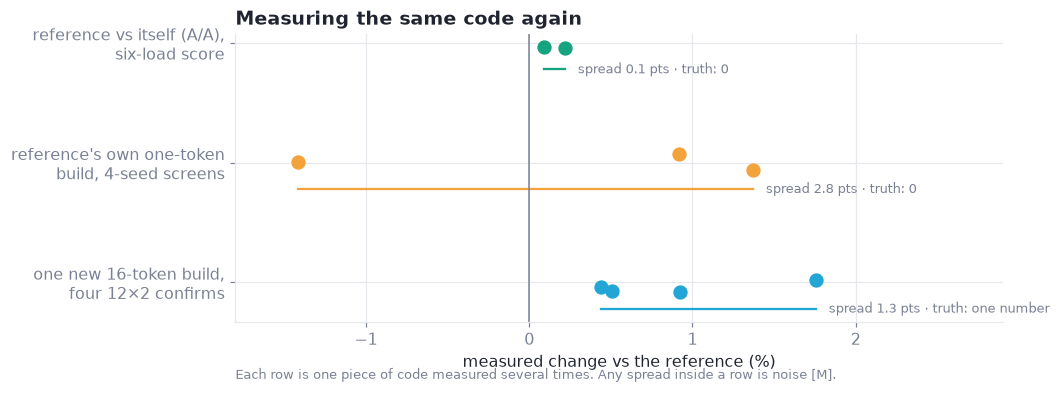

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
noise = pd.read_csv(DATA / "noise.csv")
fig, ax = plt.subplots(figsize=(9, 3.4))
groups = [("identical_d16_build_confirm_12x2", "one new 16-token build,\nfour 12×2 confirms", C["cyan"], "truth: one number"),
          ("identical_d1_build_screen_4x1", "reference's own one-token\nbuild, 4-seed screens", C["accent"], "truth: 0"),
          ("aa_six_load", "reference vs itself (A/A),\nsix-load score", C["good"], "truth: 0")]
for i, (k, lab, cc, truth) in enumerate(groups):
    v = (noise[noise.kind == k].ratio.values - 1) * 100
    ax.scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.08, 0.08, len(v)), s=70, color=cc, zorder=3)
    ax.plot([v.min(), v.max()], [i - 0.22, i - 0.22], color=cc, lw=1.5)
    ax.text(v.max() + 0.08, i - 0.22, f"spread {v.max() - v.min():.1f} pts · {truth}", va="center", fontsize=8.5, color=MUTED)
ax.axvline(0, color=MUTED, lw=1); ax.set_yticks(range(3), [g[1] for g in groups]); ax.set_xlabel("measured change vs the reference (%)")
ax.set_xlim(-1.8, 2.9); ax.set_title("Measuring the same code again")
note(ax, "Each row is one piece of code measured several times. Any spread inside a row is noise [M].")
save(fig, "noise_identical_builds"); plt.show()

## Screens nominate, confirms decide

Every design in the 514-design sweep was screened with 4 seeds; 30 finalists were re-timed at 12 seeds × 2 repeats
next to the control. For each load, take the 8 finalists with the best screen reading and measure them again: their
average gain shrinks, and on three loads it changes sign. That is **regression to the mean**: part of every screen
leader's lead was luck.

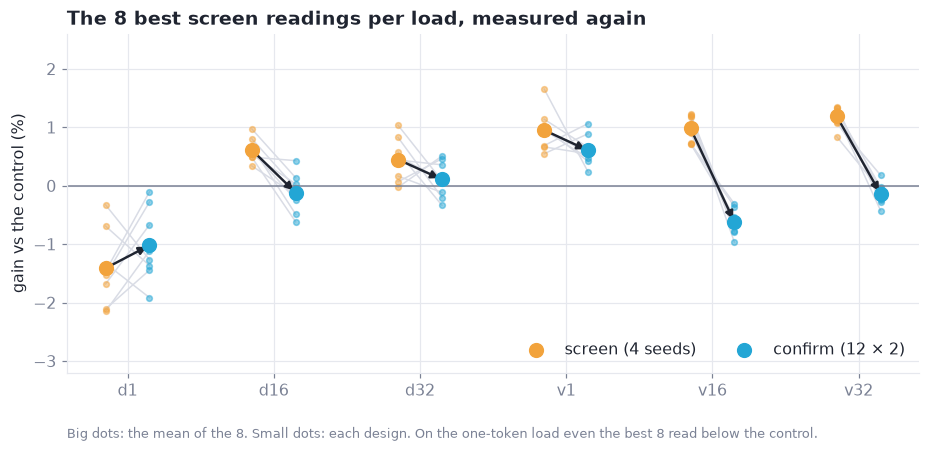

In [2]:
sw = pd.read_csv(DATA / "moe_sweep.csv")
key, LOADS = ["compute", "activation", "decoder"], ["d1", "d16", "d32", "v1", "v16", "v32"]
scr, con = sw[sw.grade == "screen_4x1"], sw[sw.grade == "confirm_12x2"]
cs = scr[scr.group == "control"].iloc[0]; cc_ = con[con.group == "control"].iloc[0]
m = scr.merge(con, on=key, suffixes=("_s", "_c")); m = m[m.group_s != "control"]
fig, ax = plt.subplots(figsize=(10, 4))
for i, L in enumerate(LOADS):
    x = (m[f"{L}_s"] / cs[L] - 1) * 100; y = (m[f"{L}_c"] / cc_[L] - 1) * 100
    top = x.nlargest(8).index
    for a, b in zip(x[top], y[top]): ax.plot([i - 0.15, i + 0.15], [a, b], color="#d9dce5", lw=1, zorder=1)
    ax.scatter(np.full(8, i - 0.15), x[top], s=14, color=C["accent"], alpha=0.5, zorder=2)
    ax.scatter(np.full(8, i + 0.15), y[top], s=14, color=C["cyan"], alpha=0.5, zorder=2)
    ax.annotate("", xy=(i + 0.15, y[top].mean()), xytext=(i - 0.15, x[top].mean()),
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.6), zorder=4)
    ax.scatter([i - 0.15], [x[top].mean()], s=80, color=C["accent"], zorder=5, label="screen (4 seeds)" if i == 0 else None)
    ax.scatter([i + 0.15], [y[top].mean()], s=80, color=C["cyan"], zorder=5, label="confirm (12 × 2)" if i == 0 else None)
ax.axhline(0, color=MUTED, lw=1); ax.set_xticks(range(6), LOADS); ax.set_ylim(-3.2, 2.6)
ax.set_ylabel("gain vs the control (%)"); ax.legend(loc="lower right", ncol=2)
ax.set_title("The 8 best screen readings per load, measured again")
note(ax, "Big dots: the mean of the 8. Small dots: each design. On the one-token load even the best 8 read below the control.")
save(fig, "noise_screen_vs_confirm"); plt.show()

## The winner's curse

Pick the best of $n$ designs that are all truly equal and measured with noise $\sigma$, and the winner reads high by
about

$$
\mathbb{E}\Big[\max_{i \le n} \varepsilon_i\Big] \approx \sigma \sqrt{2 \ln n}.
$$

With a 1% screen and 30 candidates, that is a 2.6% "gain" that does not exist. Replication, and a binding rule that
needs two samples above a margin with none negative, is what removes it.

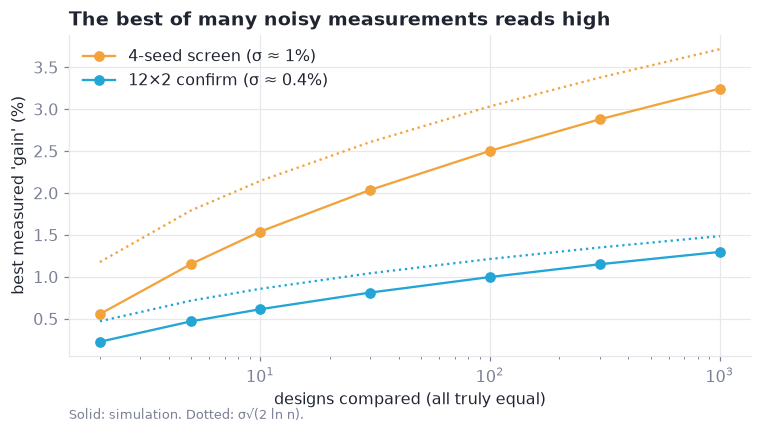

In [3]:
rng = np.random.default_rng(1)
ns = np.array([2, 5, 10, 30, 100, 300, 1000])
fig, ax = plt.subplots(figsize=(8, 3.8))
for sigma, lab, cc in ((1.0, "4-seed screen (σ ≈ 1%)", C["accent"]), (0.4, "12×2 confirm (σ ≈ 0.4%)", C["cyan"])):
    sim = [np.mean(np.max(rng.normal(0, sigma, (4000, n)), axis=1)) for n in ns]
    ax.plot(ns, sim, "o-", color=cc, label=lab)
    ax.plot(ns, sigma * np.sqrt(2 * np.log(ns)), ":", color=cc)
ax.set_xscale("log"); ax.set_xlabel("designs compared (all truly equal)"); ax.set_ylabel("best measured 'gain' (%)")
ax.set_title("The best of many noisy measurements reads high"); ax.legend()
note(ax, "Solid: simulation. Dotted: σ√(2 ln n).")
save(fig, "noise_winners_curse"); plt.show()

[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)